# Ejercicio 3: Construcción de la matriz de proyección binaria

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
X_fantoma = np.array([
[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
[0.0, 0.0, 0.8, 0.3, 0.3, 0.3, 0.0, 0.0],
[0.0, 0.8, 0.8, 0.8, 0.3, 0.3, 0.3, 0.0],
[0.0, 0.3, 0.8, 0.3, 0.3, 0.3, 0.3, 0.0],
[0.0, 0.3, 0.3, 0.3, 0.3, 0.5, 0.3, 0.0],
[0.0, 0.3, 0.3, 0.3, 0.5, 0.5, 0.5, 0.0],
[0.0, 0.0, 0.3, 0.3, 0.3, 0.5, 0.0, 0.0],
[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
], dtype=float)

In [ ]:
x_fantoma = X_fantoma.reshape(-1)

In [ ]:
def mascara_rayo(n, direccion, s):
  res = np.zeros((n, n))                                             # Inicializamos una matriz de ceros
  for i in range(0, n):                                              # Por cada fila
    for j in range(0, n):                                            # Por cada columna
      if direccion[0] * i + direccion[1] * j == s:                   # Vemos si está en el centro
        res[i, j] = 1                                                # Modificamos

  return res

a) Implementamos la función `matriz_proyeccion(n, direcciones)`, que reúne las máscaras de todos los rayos en una única matriz A: cada fila a<sub>r</sub><sup>T</sup> es la máscara M<sub>r</sub> vectorizada por filas, agrupada por dirección y ordenada por s creciente.

In [ ]:
def matriz_proyeccion(n, direcciones):
  res = []

  for direccion in direcciones:                                      # Por cada dirección (α, β)
    eses = []                                                        # Valores de s de esa dirección

    for i in range(n):                                               # Por cada fila
      for j in range(n):                                             # Por cada columna
        s = direccion[0] * i + direccion[1] * j                      # El s del rayo que pasa por ese píxel

        if s not in eses:                                            # Evitamos repetir rayos
          eses.append(s)

    for s in sorted(eses):                                           # Por cada rayo, de menor a mayor s
      res.append(mascara_rayo(n, direccion, s).reshape(-1))          # Agregamos su máscara vectorizada

  return np.array(res)

In [ ]:
direcciones = [(1, 0), (0, 1), (1, 1), (1, -1), (2, 1)]

A = matriz_proyeccion(8, direcciones)                                # n = 8 por las dimensiones del fantoma

print(A.shape)

(68, 64)


b) Construimos una lista con el par ((α, β), s) asociado a cada fila de A,
replicando el orden de la función: las direcciones tal como fueron recibidas y, dentro de cada una, los s de menor a mayor.

In [ ]:
etiquetas = []

for (alpha, beta) in direcciones:                                    # Mismo orden que en la función
  eses = sorted({alpha * i + beta * j                                # Valores distintos de s, de menor a mayor
                 for i in range(8) for j in range(8)})

  for s in eses:
    etiquetas.append(((alpha, beta), s))

print(len(etiquetas) == A.shape[0])                                  # Verificamos la correspondencia con A

for r in range(len(etiquetas)):
  ((alpha, beta), s) = etiquetas[r]
  print(f"Fila {r}: dirección ({alpha}, {beta}), s = {s}")

True
Fila 0: dirección (1, 0), s = 0
Fila 1: dirección (1, 0), s = 1
Fila 2: dirección (1, 0), s = 2
Fila 3: dirección (1, 0), s = 3
Fila 4: dirección (1, 0), s = 4
Fila 5: dirección (1, 0), s = 5
Fila 6: dirección (1, 0), s = 6
Fila 7: dirección (1, 0), s = 7
Fila 8: dirección (0, 1), s = 0
Fila 9: dirección (0, 1), s = 1
Fila 10: dirección (0, 1), s = 2
Fila 11: dirección (0, 1), s = 3
Fila 12: dirección (0, 1), s = 4
Fila 13: dirección (0, 1), s = 5
Fila 14: dirección (0, 1), s = 6
Fila 15: dirección (0, 1), s = 7
Fila 16: dirección (1, 1), s = 0
Fila 17: dirección (1, 1), s = 1
Fila 18: dirección (1, 1), s = 2
Fila 19: dirección (1, 1), s = 3
Fila 20: dirección (1, 1), s = 4
Fila 21: dirección (1, 1), s = 5
Fila 22: dirección (1, 1), s = 6
Fila 23: dirección (1, 1), s = 7
Fila 24: dirección (1, 1), s = 8
Fila 25: dirección (1, 1), s = 9
Fila 26: dirección (1, 1), s = 10
Fila 27: dirección (1, 1), s = 11
Fila 28: dirección (1, 1), s = 12
Fila 29: dirección (1, 1), s = 13
Fila 30: di

c)

In [ ]:
direcciones_c = [(1, 0), (0, 1)]

A_c = matriz_proyeccion(8, direcciones_c)

print(A_c.shape[0])
print(A_c.shape == (16, 8 * 8))

16
True


Chequeamos que A tiene 16 filas y que $A \in \mathbb{R}^{16 \times 64}$

d)

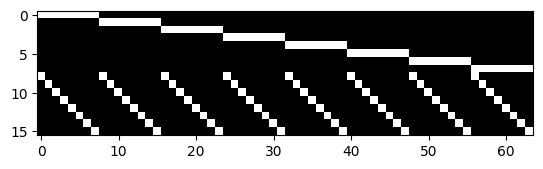

In [ ]:
plt.imshow(A_c, cmap = 'gray')
plt.show()

d) Cada fila de A representa un rayo: es su máscara M<sub>r</sub> vectorizada, con un 1 en cada píxel que atraviesa y un 0 en el resto. Cada columna representa un píxel de la imagen, y sus entradas indican en qué rayos participa ese píxel.

La imagen muestra que cada fila tiene solo 8 entradas blancas sobre 64, es decir que el 87,5% de A<sub>c</sub> son ceros. Esto es porque cada rayo atraviesa apenas n de los n² píxeles, de modo que la proporción de ceros crece con el tamaño de la imagen. La diferencia de patrón entre ambas mitades no refleja rayos de distinta longitud (todos tocan 8 píxeles), sino cómo la vectorización por filas ordena los píxeles: contigua para las filas de la imagen, espaciada de a n para las columnas.

e)

True
True


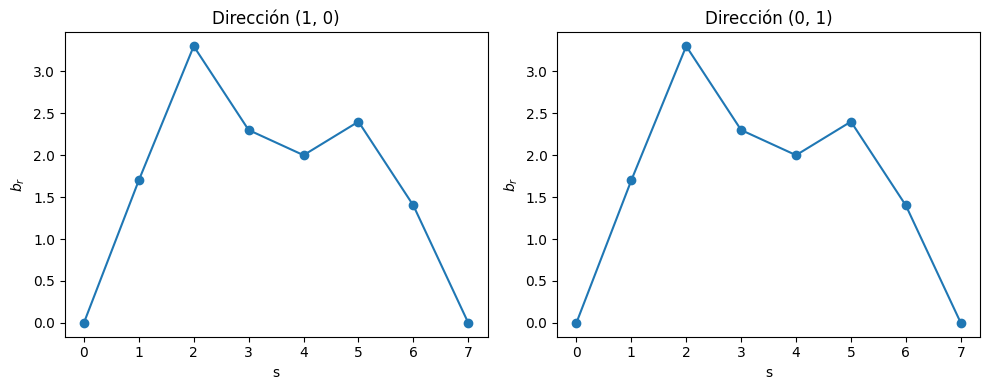

In [ ]:
b = A_c @ x_fantoma

print(np.allclose(b[:8], X_fantoma.sum(axis=1)))
print(np.allclose(b[8:], X_fantoma.sum(axis=0)))

fig, ax = plt.subplots(1, 2, figsize=(10, 4))

ax[0].plot(b[:8], marker='o')
ax[0].set_title("Dirección (1, 0)")
ax[0].set_xlabel("s")
ax[0].set_ylabel("$b_r$")

ax[1].plot(b[8:], marker='o')
ax[1].set_title("Dirección (0, 1)")
ax[1].set_xlabel("s")
ax[1].set_ylabel("$b_r$")

plt.tight_layout()
plt.show()